# Business Data Preparation, Comparative and Value-Based Analysis
### Adidas US Sales Analysis

**Dataset:** Adidas US Sales Datasets
**Source:** Kaggle (Adidas Sales Dataset, Heemali Chaudhari) / mirrored on GitHub
**Objective:** Understand how raw business data is transformed into meaningful information using
data preparation, transformation, comparative analysis, Pareto analysis, and ABC analysis.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


## 2. Dataset Understanding

The dataset contains Adidas US sales transactions for 2020–2021, covering six retailers across
five regions, six product lines, and three sales methods (in-store, outlet, online).


In [2]:
df = pd.read_csv("adidas_raw.csv")
print("Shape:", df.shape)
df.head()


Shape: (9648, 13)


,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Operating Margin,Sales Method
0,Foot Locker,1185732,01/01/2020,Northeast,New York,New York,Men's Street Footwear,$50.00,1200,"$6,00,000","$3,00,000",50%,In-store
1,Foot Locker,1185732,02/01/2020,Northeast,New York,New York,Men's Athletic Footwear,$50.00,1000,"$5,00,000","$1,50,000",30%,In-store
2,Foot Locker,1185732,03/01/2020,Northeast,New York,New York,Women's Street Footwear,$40.00,1000,"$4,00,000","$1,40,000",35%,In-store
3,Foot Locker,1185732,04/01/2020,Northeast,New York,New York,Women's Athletic Footwear,$45.00,850,"$3,82,500","$1,33,875",35%,In-store
4,Foot Locker,1185732,05/01/2020,Northeast,New York,New York,Men's Apparel,$60.00,900,"$5,40,000","$1,62,000",30%,In-store


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9648 entries, 0 to 9647
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Retailer          9648 non-null   str  
 1   Retailer ID       9648 non-null   int64
 2   Invoice Date      9648 non-null   str  
 3   Region            9648 non-null   str  
 4   State             9648 non-null   str  
 5   City              9648 non-null   str  
 6   Product           9648 non-null   str  
 7   Price per Unit    9648 non-null   str  
 8   Units Sold        9648 non-null   int64
 9   Total Sales       9648 non-null   str  
 10  Operating Profit  9648 non-null   str  
 11  Operating Margin  9648 non-null   str  
 12  Sales Method      9648 non-null   str  
dtypes: int64(2), str(11)
memory usage: 980.0 KB


In [4]:
print("Retailers:", df['Retailer'].unique())
print("Regions:", df['Region'].unique())
print("Products:", df['Product'].unique())
print("Sales Methods:", df['Sales Method'].unique())
print("Number of states:", df['State'].nunique())


Retailers: <StringArray>
['Foot Locker', 'Walmart', 'Sports Direct', 'West Gear', 'Kohl's', 'Amazon']
Length: 6, dtype: str
Regions: <StringArray>
['Northeast', 'South', 'West', 'Midwest', 'Southeast']
Length: 5, dtype: str
Products: <StringArray>
[    'Men's Street Footwear',   'Men's Athletic Footwear',
   'Women's Street Footwear', 'Women's Athletic Footwear',
             'Men's Apparel',           'Women's Apparel']
Length: 6, dtype: str
Sales Methods: <StringArray>
['In-store', 'Outlet', 'Online']
Length: 3, dtype: str
Number of states: 50


## 3. Data Preprocessing

The raw file has several real-world data quality issues that must be resolved before analysis:

- `Price per Unit`, `Total Sales`, and `Operating Profit` are stored as **text strings** with
  currency symbols and comma separators (e.g. `"$6,00,000 "`), not numeric types.
- `Operating Margin` is stored as a percentage string (e.g. `"50%"`).
- `Invoice Date` is stored as text rather than a proper date type.
- Column names contain spaces, which is inconvenient for coding — these are standardized.

Steps performed:


In [5]:
# 3.1 Missing values and duplicates
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
 Retailer            0
Retailer ID         0
Invoice Date        0
Region              0
State               0
City                0
Product             0
Price per Unit      0
Units Sold          0
Total Sales         0
Operating Profit    0
Operating Margin    0
Sales Method        0
dtype: int64

Duplicate rows: 0


No missing values or duplicate rows were found in the raw file, so no imputation or row
removal was required. (If missing values had been present, numeric fields would be imputed with
the median — robust to the outliers seen in sales data — and categorical fields with the mode.)


In [6]:
# 3.2 Standardize column names
df.columns = [c.strip().lower().replace(' ', '_').replace('-', '_') for c in df.columns]
print(df.columns.tolist())


['retailer', 'retailer_id', 'invoice_date', 'region', 'state', 'city', 'product', 'price_per_unit', 'units_sold', 'total_sales', 'operating_profit', 'operating_margin', 'sales_method']


In [7]:
# 3.3 Clean currency columns: strip $ and commas, convert to float
def clean_currency(series):
    return (series.astype(str)
                  .str.replace('$', '', regex=False)
                  .str.replace(',', '', regex=False)
                  .str.strip()
                  .astype(float))

df['price_per_unit'] = clean_currency(df['price_per_unit'])
df['total_sales'] = clean_currency(df['total_sales'])
df['operating_profit'] = clean_currency(df['operating_profit'])

# 3.4 Clean percentage column
df['operating_margin'] = (df['operating_margin'].astype(str)
                                                  .str.replace('%', '', regex=False)
                                                  .astype(float) / 100)

# 3.5 Correct data type for date
df['invoice_date'] = pd.to_datetime(df['invoice_date'], format='%d/%m/%Y', errors='coerce')

df[['price_per_unit', 'total_sales', 'operating_profit', 'operating_margin', 'invoice_date']].head()


,price_per_unit,total_sales,operating_profit,operating_margin,invoice_date
0,50.00,"600,000.00","300,000.00",0.50,2020-01-01
1,50.00,"500,000.00","150,000.00",0.30,2020-01-02
2,40.00,"400,000.00","140,000.00",0.35,2020-01-03
3,45.00,"382,500.00","133,875.00",0.35,2020-01-04
4,60.00,"540,000.00","162,000.00",0.30,2020-01-05


In [8]:
print("Any invalid dates after parsing:", df['invoice_date'].isnull().sum())
df.dtypes


Any invalid dates after parsing: 0


retailer                       str
retailer_id                  int64
invoice_date        datetime64[us]
region                         str
state                          str
city                           str
product                        str
price_per_unit             float64
units_sold                   int64
total_sales                float64
operating_profit           float64
operating_margin           float64
sales_method                   str
dtype: object

## 4. Data Transformation

Two transformations are applied:

1. **Date decomposition** — `invoice_date` is broken into `year`, `month`, and `month_name`
   columns. This is suitable because the raw date string is not directly usable for grouping or
   trend analysis; splitting it out enables month-over-month and year-over-year comparisons.
2. **Log transformation of `total_sales`** — `total_sales` is heavily right-skewed (a small
   number of very large transactions). A log transform (`log1p`) compresses the scale and makes
   the distribution closer to normal, which is useful for statistical comparison and for reducing
   the visual dominance of outliers in plots. The original `total_sales` column is preserved for
   business-value calculations (Pareto/ABC), and the transformed column is used only for
   distribution comparison.


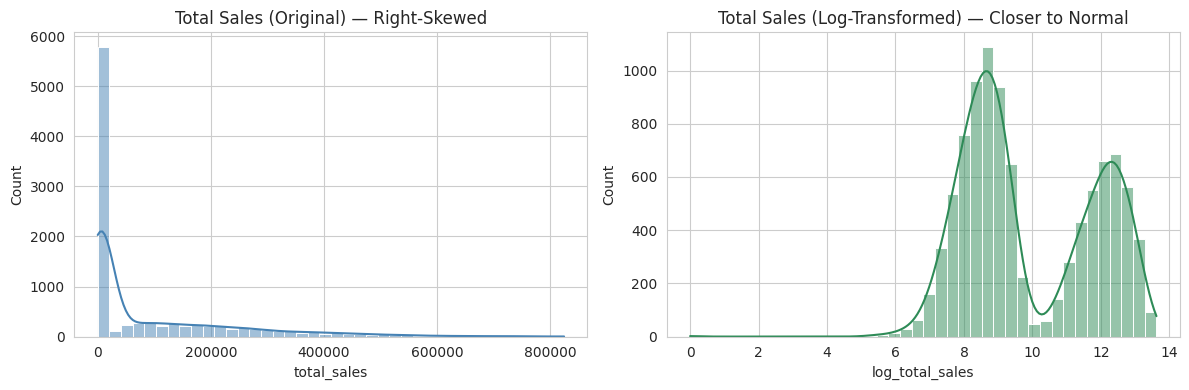

In [9]:
df['year'] = df['invoice_date'].dt.year
df['month'] = df['invoice_date'].dt.month
df['month_name'] = df['invoice_date'].dt.strftime('%b')

df['log_total_sales'] = np.log1p(df['total_sales'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['total_sales'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Total Sales (Original) — Right-Skewed')
sns.histplot(df['log_total_sales'], bins=40, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Total Sales (Log-Transformed) — Closer to Normal')
plt.tight_layout()
plt.savefig('fig_transformation.png', dpi=150)
plt.show()


## 5. Comparative Analysis

### 5.1 Region-wise comparison


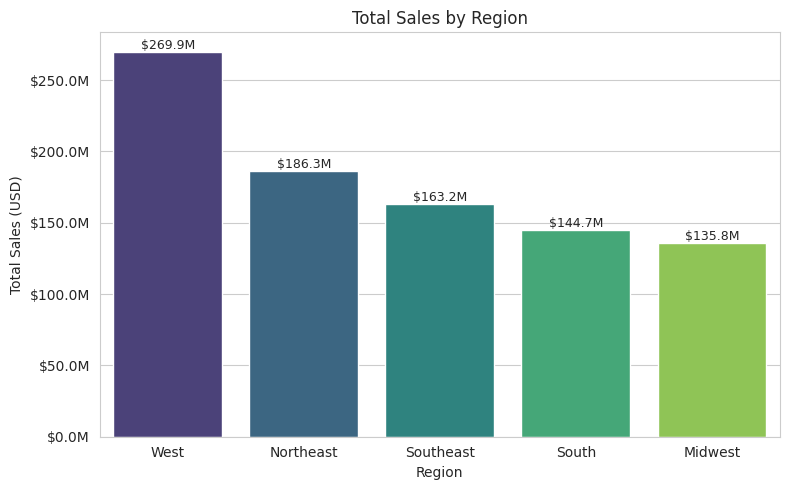

region
West        269,943,182.00
Northeast   186,324,067.00
Southeast   163,171,236.00
South       144,663,181.00
Midwest     135,800,459.00
Name: total_sales, dtype: float64

In [10]:
region_sales = df.groupby('region')['total_sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=region_sales.index, y=region_sales.values, hue=region_sales.index,
                  palette='viridis', legend=False)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.title('Total Sales by Region')
plt.ylabel('Total Sales (USD)')
plt.xlabel('Region')
for i, v in enumerate(region_sales.values):
    plt.text(i, v, f'${v/1e6:.1f}M', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('fig_region_sales.png', dpi=150)
plt.show()
region_sales


**Interpretation:** The West and Northeast regions generate the highest total sales, while
the Midwest lags behind. This points to stronger retail presence or brand demand in the
higher-performing regions and highlights the Midwest as a target for growth initiatives.


### 5.2 Product-wise comparison

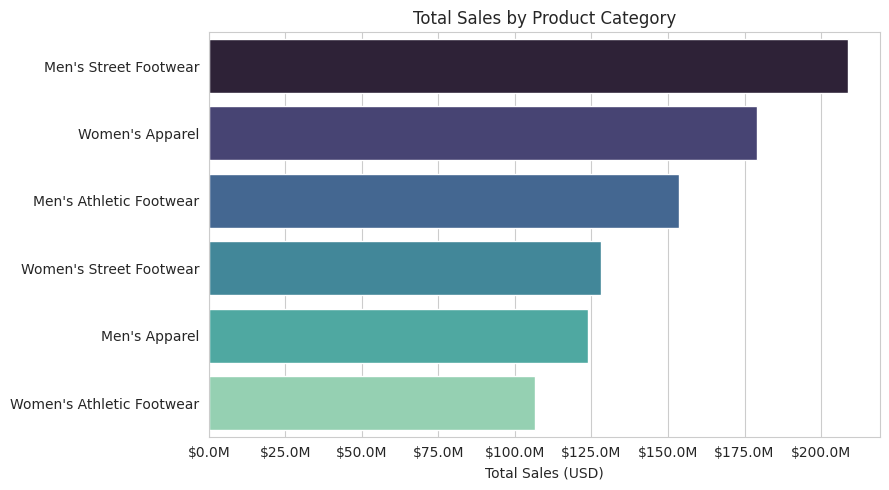

product
Men's Street Footwear       208,826,244.00
Women's Apparel             179,038,860.00
Men's Athletic Footwear     153,673,680.00
Women's Street Footwear     128,002,813.00
Men's Apparel               123,728,632.00
Women's Athletic Footwear   106,631,896.00
Name: total_sales, dtype: float64

In [11]:
product_sales = df.groupby('product')['total_sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=product_sales.values, y=product_sales.index, hue=product_sales.index,
                  palette='mako', legend=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.title('Total Sales by Product Category')
plt.xlabel('Total Sales (USD)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('fig_product_sales.png', dpi=150)
plt.show()
product_sales


**Interpretation:** Men's Street Footwear and Women's Apparel are the top revenue-generating
product lines, while Men's Apparel trails the others. Footwear categories collectively outperform
apparel, suggesting footwear is the stronger anchor category for Adidas in the US market.


### 5.3 Box-and-whisker comparison

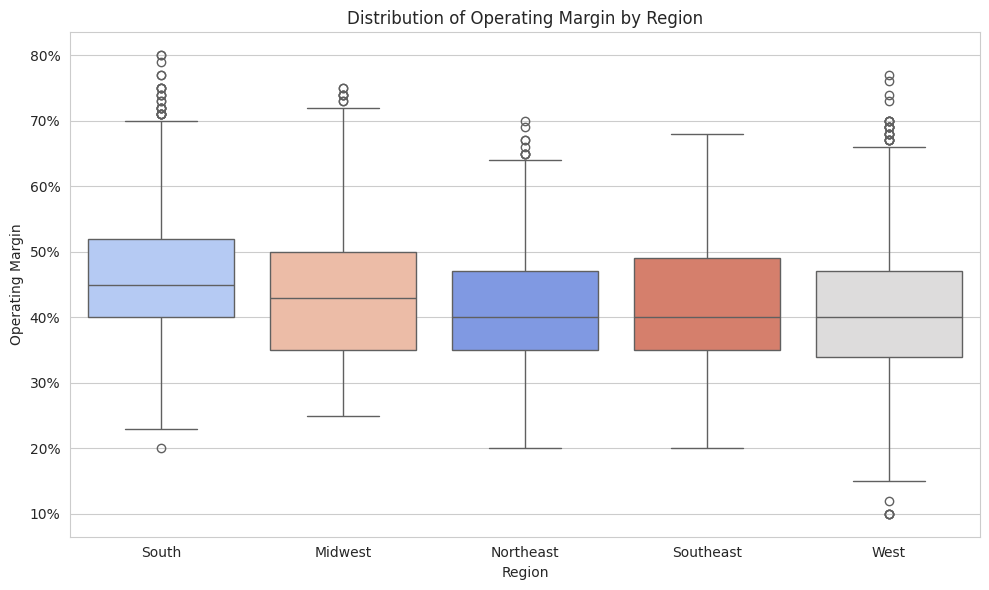

In [12]:
plt.figure(figsize=(10, 6))
order = df.groupby('region')['operating_margin'].median().sort_values(ascending=False).index
sns.boxplot(x='region', y='operating_margin', data=df, order=order, hue='region',
            palette='coolwarm', legend=False)
plt.title('Distribution of Operating Margin by Region')
plt.ylabel('Operating Margin')
plt.xlabel('Region')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0%}'))
plt.tight_layout()
plt.savefig('fig_boxplot_margin.png', dpi=150)
plt.show()


**Interpretation:** Operating margin is broadly similar in its median across regions, but the
spread (variability) differs — some regions show a wider interquartile range and more low-margin
outliers, indicating less consistent profitability at the transaction level even where median
performance looks comparable.


## 6. Pareto Analysis (80/20 Rule)

To identify which parts of the business drive the majority of value, Pareto analysis is applied
to **sales by state** (a more granular breakdown than region), since the assignment calls for
identifying the major contributors to total business value.


In [13]:
state_sales = df.groupby('state')['total_sales'].sum().sort_values(ascending=False).reset_index()
state_sales['cumulative_pct'] = 100 * state_sales['total_sales'].cumsum() / state_sales['total_sales'].sum()
state_sales['rank'] = range(1, len(state_sales) + 1)

n_states_80 = (state_sales['cumulative_pct'] <= 80).sum() + 1
print(f"Number of states contributing to ~80% of total sales: {n_states_80} out of {len(state_sales)}")
state_sales.head(15)


Number of states contributing to ~80% of total sales: 31 out of 50


,state,total_sales,cumulative_pct,rank
0,New York,"64,229,039.00",7.14,1
1,California,"60,174,133.00",13.82,2
2,Florida,"59,283,714.00",20.41,3
3,Texas,"46,359,746.00",25.56,4
4,South Carolina,"29,285,637.00",28.82,5
5,Washington,"26,330,718.00",31.74,6
6,North Carolina,"23,956,531.00",34.41,7
7,Louisiana,"23,750,781.00",37.05,8
8,Hawaii,"22,282,457.00",39.52,9
9,Virginia,"21,575,040.00",41.92,10


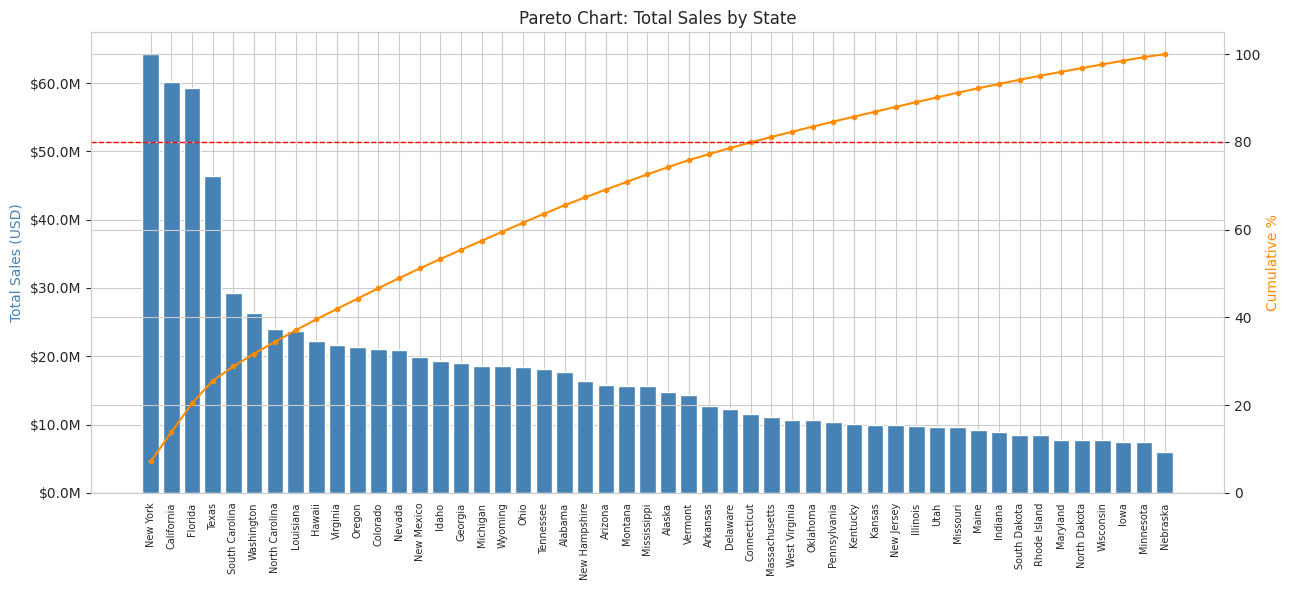

In [14]:
fig, ax1 = plt.subplots(figsize=(13, 6))
ax1.bar(state_sales['state'], state_sales['total_sales'], color='steelblue')
ax1.set_ylabel('Total Sales (USD)', color='steelblue')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax1.tick_params(axis='x', rotation=90, labelsize=7)

ax2 = ax1.twinx()
ax2.plot(state_sales['state'], state_sales['cumulative_pct'], color='darkorange', marker='o', markersize=3)
ax2.axhline(80, color='red', linestyle='--', linewidth=1)
ax2.set_ylabel('Cumulative %', color='darkorange')
ax2.set_ylim(0, 105)

plt.title('Pareto Chart: Total Sales by State')
plt.tight_layout()
plt.savefig('fig_pareto.png', dpi=150)
plt.show()


**Interpretation:** The Pareto chart shows that a relatively small subset of states accounts
for roughly 80% of total sales value (see the count printed above), consistent with the classic
80/20 rule. These top states represent the highest-priority markets for inventory allocation,
marketing spend, and retailer partnerships.


## 7. ABC Analysis

States are classified into A, B, and C tiers based on their cumulative contribution to total
sales:

- **Class A** — cumulative contribution up to 70% (high-value, top priority)
- **Class B** — cumulative contribution from 70% to 90% (medium value)
- **Class C** — cumulative contribution from 90% to 100% (low value, long tail)


In [15]:
def classify(cum_pct):
    if cum_pct <= 70:
        return 'A'
    elif cum_pct <= 90:
        return 'B'
    else:
        return 'C'

state_sales['abc_class'] = state_sales['cumulative_pct'].apply(classify)

abc_summary = state_sales.groupby('abc_class').agg(
    num_states=('state', 'count'),
    total_sales=('total_sales', 'sum')
)
abc_summary['pct_of_total_sales'] = 100 * abc_summary['total_sales'] / abc_summary['total_sales'].sum()
abc_summary


,num_states,total_sales,pct_of_total_sales
abc_class,,,
A,23,"622,154,160.00",69.14
B,15,"179,441,497.00",19.94
C,12,"98,306,468.00",10.92


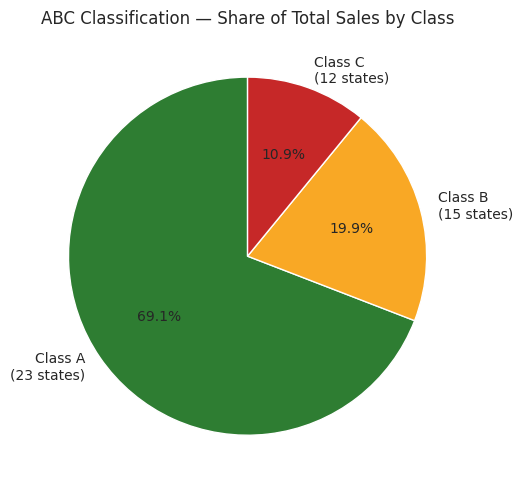

In [16]:
plt.figure(figsize=(7, 5))
colors = {'A': '#2E7D32', 'B': '#F9A825', 'C': '#C62828'}
plt.pie(abc_summary['total_sales'], labels=[f'Class {c}\n({abc_summary.loc[c,"num_states"]} states)' for c in abc_summary.index],
        autopct='%1.1f%%', colors=[colors[c] for c in abc_summary.index], startangle=90)
plt.title('ABC Classification — Share of Total Sales by Class')
plt.tight_layout()
plt.savefig('fig_abc.png', dpi=150)
plt.show()


**Interpretation:** A small number of Class A states generate the majority of total sales
value, while Class C contains many states each contributing very little individually. This
confirms that business focus and resources should be concentrated on Class A states first, with
Class B monitored for growth potential and Class C managed for efficiency rather than growth.


## 8. Business Insights and Recommendations

**Key Insights**

- Sales performance is highly concentrated: Class A states (23 of 50) generate about 69% of
  total revenue, consistent with the Pareto principle.
- The West and Northeast regions outperform other regions in total sales, while the Midwest
  underperforms.
- Footwear categories (particularly Men's Street Footwear) outsell apparel categories overall.
- Operating margin medians are broadly similar across regions, but variability differs, pointing
  to inconsistent profitability execution in some regions even where revenue is comparable.
- The log transformation confirms that a small number of high-value transactions disproportionately
  shape total sales figures.

**Recommendations**

1. Prioritize inventory, marketing budget, and retailer partnerships in Class A states and the
   West/Northeast regions, where demand is proven.
2. Investigate the Midwest region's underperformance — pricing, retailer mix, and marketing
   reach should be reviewed.
3. Use the footwear category's strength as an anchor for cross-selling apparel, particularly
   Women's Apparel, which is already a strong performer.
4. Standardize discounting and margin practices in regions with wide margin variability to protect
   profitability, not just revenue.
5. Continue monitoring Class B states for graduation to Class A as they may represent
   under-tapped growth opportunities.
